# Задача обучения с учителем: что дано, что предсказываем, как проверяем

ФПМИ.Будущее · ИИ · Прекурс · Занятие 5

На занятии 2 вы считали рейтинг `X @ w + b`, и веса `w` вам выдали готовыми. В настоящих задачах весов никто не знает. Зато есть примеры, где правильный ответ уже известен, — по ним модель подбирает параметры сама.

Сегодня научимся формулировать такую задачу, обучим первую модель в sklearn и проверим её честно.

## 0. Зачем

Любая задача машинного обучения начинается с трёх вопросов:

1. **Что дано?** Какие объекты и что мы про них знаем.
2. **Что предсказываем?** Число или класс.
3. **Как проверим?** Как понять, что модель действительно что-то умеет, а не просто запомнила ответы.

С этого начинается почти каждая ML-задача на олимпиаде и в отборе: прочитать условие и ответить на три вопроса.

## 1. Объект, признаки, таргет

Одна строка таблицы — один пассажир «Титаника».

In [2]:
import os
import numpy as np
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
local = "data/titanic.csv"   # копия в папке занятия — если интернета нет
titanic = pd.read_csv(local if os.path.exists(local) else url)
print("Форма таблицы:", titanic.shape)
titanic[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]].head()

Форма таблицы: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500


| Столбец | Что значит |
| --- | --- |
| `survived` | выжил (1) или нет (0) |
| `pclass` | класс билета: 1 — самый дорогой, 3 — самый дешёвый |
| `sex` | пол |
| `age` | возраст, лет |
| `sibsp` | сколько братьев, сестёр и супругов плыло вместе с пассажиром |
| `parch` | сколько родителей и детей плыло вместе с пассажиром |
| `fare` | цена билета |

Первая строка: мужчина 22 лет, билет третьего класса за 7.25, плыл с одним родственником. Не выжил.

Хотим по тому, что известно о пассажире **до** крушения, предсказать, выживет ли он.

- **Объект** — то, про что делаем предсказание: один пассажир, одна строка.
- **Признаки** — то, что мы знаем про объект заранее: класс, возраст, родственники, цена билета.
- **Таргет** (целевая переменная) — то, что предсказываем: `survived`.

**Обучение с учителем** — так называют задачу, в которой есть объекты с уже известным таргетом. «Учитель» — это правильные ответы: модель смотрит на них и учится.

Как на занятии 2: признаки собираем в матрицу `X` (строки — объекты, столбцы — признаки), таргет — в вектор `y`. Сегодня берём пять числовых признаков. В `age` есть пропуски — заполним их медианой, как на занятии 3.

In [3]:
features = ["pclass", "age", "sibsp", "parch", "fare"]
X = titanic[features].copy()
X["age"] = X["age"].fillna(X["age"].median())
y = titanic["survived"]

print("Форма X:", X.shape)
print("Форма y:", y.shape)
print("Доля выживших:", y.mean().round(3))

Форма X: (891, 5)
Форма y: (891,)
Доля выживших: 0.384


**Вопрос** В таблице есть столбец `alive` — «yes» или «no». Добавим его в признаки: модель станет точнее?

**Посложнее** А цену билета `fare` брать можно? А номер спасательной шлюпки, если бы он был в таблице?

<details>
<summary>Показать ответ</summary>

Модель станет угадывать 100% — и на train, и на test: `alive` — это тот же `survived`, только словами. Но пользы от неё ноль: когда пассажир садится на корабль, этого столбца ещё не существует.

**Вывод для ML:** признаки — только то, что известно **до** момента предсказания. Столбец, в котором подсмотрен ответ, называют **утечкой**. Если модель вдруг выдаёт почти 100%, первым делом ищите утечку.

★ Цену билета знаем при посадке — можно. Номер шлюпки — нельзя: шлюпку получили только спасшиеся, это утечка, просто хорошо спрятанная.

</details>

## 2. Регрессия и классификация

`survived` принимает два значения: 0 или 1. Ответ либо верный, либо нет.

Если бы мы по остальным столбцам предсказывали цену билета `fare`, ответом было бы число — и промах на 1 фунт был бы лучше промаха на 100.

- **Регрессия** — таргет число; ошибиться можно «чуть-чуть» или «сильно».
- **Классификация** — таргет один из нескольких классов; ответ либо верный, либо нет.

Тип задачи определяется таргетом, а не признаками.

**Вопрос** Регрессия или классификация?

1. Цена квартиры по площади, этажу и району.
2. Письмо — спам или нет.
3. Сколько человек придёт на концерт.
4. Рубрика новости: спорт, политика или наука.
5. Выживет ли пассажир «Титаника».

**Посложнее** Оценка за экзамен: 2, 3, 4 или 5?

<details>
<summary>Показать ответ</summary>

1 — Р. 2 — К. 3 — Р: ответ целый, но это количество, и промах на 2 человека лучше промаха на 200. 4 — К: классов три, их может быть больше двух. 5 — К, это наша задача.

★ Можно и так и так. Как классификация: четыре класса, но тогда перепутать 5 с 2 так же плохо, как 5 с 4. Как регрессия: модель знает, что 4 ближе к 5, чем 2. Выбор зависит от того, как мы наказываем за ошибку, — это следующий раздел.

**Вывод для ML:** первым делом смотрим на таргет. Число, где важна величина промаха, — регрессия. Метка из списка — классификация.

</details>

## 3. Модель и функция потерь

**Модель** — это функция: на входе признаки объекта, на выходе предсказание. У неё есть **параметры** — ручки, которые можно крутить. На занятии 2 модель была `x @ w + b`, параметры — `w` и `b`.

Возьмём для «Титаника» самую простую модель с одним параметром `t`: «пассажир выжил, если номер класса его билета не больше `t`». При `t = 0` модель говорит «все погибли», при `t = 3` — «все выжили».

Какое `t` лучше? Нужно число, которое показывает, насколько модель ошибается. Такое число называют **функцией потерь**. Для начала возьмём самую понятную — долю неправильных ответов.

**До запуска:** какое `t`, по-вашему, даст меньше всего ошибок?

In [4]:
for t in [0, 1, 2, 3]:
    pred = (X["pclass"] <= t).astype(int)   # 1 — «выжил», 0 — «погиб»
    print("t =", t, "→ доля ошибок:", (pred != y).mean().round(3))

t = 0 → доля ошибок: 0.384
t = 1 → доля ошибок: 0.321
t = 2 → доля ошибок: 0.332
t = 3 → доля ошибок: 0.616


Лучше всего `t = 1`: «выжили только пассажиры первого класса». Мы только что **обучили модель**: перебрали значения параметра и выбрали то, при котором функция потерь меньше всего.

У настоящих моделей параметров тысячи, все значения не переберёшь. Их подбирают градиентным спуском из занятия 4.

## 4. Train и test

Представьте экзамен, на котором дают те же задачи, что были в домашке, — и ответы к ним вы уже видели. Пятёрку можно получить, просто запомнив ответы. Проверит ли такой экзамен, что вы что-то поняли?

С моделью так же. Если мерить качество на тех же объектах, на которых она училась, мы не узнаем, как она сработает на новых. Поэтому данные заранее делят на две части:

- **train** (обучающая выборка) — на ней модель учится;
- **test** (тестовая выборка) — её модель при обучении не видит, на ней проверяем.

Делит функция `train_test_split`: перемешивает строки и откладывает в test долю `test_size`. `random_state` фиксирует перемешивание: с одним и тем же числом разбиение у всех получается одинаковым.

**Вопрос** В датасете 891 пассажир, `test_size=0.2`, а 891 · 0.2 = 178.2. Сколько строк окажется в test?

<details>
<summary>Показать ответ</summary>

179: sklearn округляет размер test вверх. В train остаётся 712.

Порядок четырёх переменных слева важен: сначала обе части `X`, потом обе части `y`.

</details>

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)




Train: (712, 5) (712,)
Test:  (179, 5) (179,)


### Мини-задача 1. Доля выживших в test

Найдите долю выживших (`survived = 1`) среди пассажиров, попавших в test.

**Ожидаемая форма ответа:** число от 0 до 1, округлять не нужно.

**Решение**

In [10]:
share_test = y_test.mean()   # среднее столбца из 0 и 1 — это доля единиц
print("Доля выживших в test:", share_test.round(4))

Доля выживших в test: 0.4134


In [ ]:
assert np.isclose(share_test, 0.4134, atol=1e-4)

print("Мини-задача 1: тесты пройдены")

Мини-задача 1: тесты пройдены


**Посложнее** Во всём датасете выживших 0.384, в train — 0.376, в test — 0.413. Почему доли разные? Что будет при другом `random_state`?

<details>
<summary>Показать ответ</summary>

Разбиение случайное, а в test всего 179 человек — в небольшой выборке доля «гуляет». При другом `random_state` получится другая доля, например 0.408 или 0.385.

Если нужно, чтобы доля в test совпадала с долей во всём датасете, есть параметр `stratify=y`: с ним в test будет 0.385 — почти как 0.384 во всём датасете.

</details>

### Модель-зубрила

**Вопрос** Модель ответила правильно на 95% пассажиров из train. Хорошая модель?

<details>
<summary>Показать ответ</summary>

Неизвестно. Такой результат бывает и у модели, которая ничего не поняла, а просто запомнила ответы. Проверим прямо сейчас.

</details>

Напишем самую ленивую модель — **зубрилу**. Она запоминает каждого пассажира из train вместе с ответом. Встречает знакомого — отвечает по памяти. Незнакомого — говорит «погиб», потому что так было с большинством.

In [11]:
memory = {tuple(row): answer for row, answer in zip(X_train.values, y_train)}

def zubrila(X_new):
    return np.array([memory.get(tuple(row), 0) for row in X_new.values])

print("Запомнила разных пассажиров:", len(memory))

Запомнила разных пассажиров: 580


**Вопрос** Какая доля правильных ответов будет у зубрилы на train? А на test?

<details>
<summary>Показать ответ</summary>

На train — 0.954: она помнит почти всех. На test — 0.581, **хуже**, чем у модели «все погибли» (0.587). Зубрила ничему не научилась, она запомнила ответы. Увидеть это можно только на test.

**Вывод для ML:** качество на train показывает, насколько хорошо модель запомнила данные. Научилась ли она чему-то, показывает только test.

</details>

In [12]:
print("Зубрила, доля верных на train:", (zubrila(X_train) == y_train).mean().round(3))
print("Зубрила, доля верных на test: ", (zubrila(X_test) == y_test).mean().round(3))
print("Модель «все погибли» на test: ", (y_test == 0).mean().round(3))

Зубрила, доля верных на train: 0.954
Зубрила, доля верных на test:  0.581
Модель «все погибли» на test:  0.587


**Посложнее** Почему зубрила ошибается даже на train? Она же всех помнит. И почему разных пассажиров 580, а не 712?

<details>
<summary>Показать ответ</summary>

В train есть пассажиры с одинаковыми признаками и разной судьбой. Например, 14 пассажиров третьего класса, плывших в одиночку, с билетом за 7.75 и неизвестным возрастом (после заполнения всем 28): 6 выжили, 8 нет. Для словаря это один ключ, и помнит он только последний ответ. Всего таких групп 21, в них 74 человека.

Значит, по этим пяти признакам судьбу нельзя угадать без ошибок в принципе. Никакая модель не наберёт 100% на честном test.

Кстати, в этой группе из 14 выжили 5 женщин из 6 и 1 мужчина из 8. Их различает пол — а его среди наших признаков нет. С полом модель угадала бы в этой группе 12 человек из 14, а без него — не больше 8.

</details>

**Вопрос** А если оставить в test только двух пассажиров — можно верить такой проверке?

<details>
<summary>Показать ответ</summary>

Нельзя. Каждый пассажир — половина оценки: модель получит 0%, 50% или 100%, и это больше скажет о везении, чем о модели. Test должен быть достаточно большим, поэтому обычно откладывают 20–30% данных. Слишком большой test тоже плох: на обучение останется мало.

</details>

## 5. `fit` и `predict`

В sklearn у любой модели одни и те же три шага:

```python
model = Модель(настройки)        # 1. создать
model.fit(X_train, y_train)      # 2. обучить: подобрать параметры по train
model.predict(X_new)             # 3. предсказать для новых объектов
```

Линейная регрессия (занятие 6) и классификаторы (занятие 9) устроены так же — меняется только первая строка.

Возьмём готовую модель — **дерево решений** (`DecisionTreeClassifier`). Как оно устроено внутри, разберём на занятии 9. Сегодня пользуемся им как чёрным ящиком: на входе признаки, на выходе 0 или 1.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Предсказания для первых 10 из test:", y_pred[:10])
print("Правильные ответы:                 ", y_test.values[:10])

Предсказания для первых 10 из test: [0 0 1 1 0 1 0 0 0 0]
Правильные ответы:                  [1 0 0 1 1 1 1 0 1 1]


Совпало 4 из 10. Посчитаем по всему test.

### Мини-задача 2. Доля верных ответов

Посчитайте долю правильных предсказаний модели на test: сравните `y_pred` с `y_test`.

**Ожидаемая форма ответа:** число от 0 до 1.

**Решение**

In [ ]:
acc_test = (y_pred == y_test).mean()
print("Доля верных ответов на test:", acc_test.round(3))

Доля верных ответов на test: 0.631


In [ ]:
assert np.isclose(acc_test, model.score(X_test, y_test))

print("Мини-задача 2: тесты пройдены")

Мини-задача 2: тесты пройдены


## 6. Честная проверка

**Задача.** Модель уже обучена на train. Найдите долю правильных ответов на train и на test. Одинаковые ли они? Что это говорит о модели?

**Вопрос** На train доля верных будет больше, меньше или такая же, как на test? Насколько?

<details>
<summary>Показать ответ</summary>

На train — 0.959, на test — 0.631. Разрыв огромный. Дерево повело себя как зубрила (у неё было 0.954 на train): без ограничений оно задаёт вопросы, пока не разложит почти каждого пассажира из train по своей клетке, — и запоминает ответы.

</details>

In [ ]:
print("Дерево, доля верных на train:", round(model.score(X_train, y_train), 3))
print("Дерево, доля верных на test: ", round(model.score(X_test, y_test), 3))

Дерево, доля верных на train: 0.959
Дерево, доля верных на test:  0.631


У дерева есть настройка `max_depth` — сколько вопросов подряд оно может задать. Ограничим тремя: запомнить каждого пассажира за три вопроса не получится, придётся искать общие правила.

**Вопрос** Что станет с долей верных на train и на test при `max_depth=3`?

<details>
<summary>Показать ответ</summary>

Train — 0.733 (упала), test — 0.704 (выросла). Разрыв почти исчез. Модель, которая хуже запоминает, лучше работает на новых пассажирах.

Это явление называют **переобучением**: слишком гибкая модель запоминает случайности train вместо общих закономерностей.

</details>

In [ ]:
small = DecisionTreeClassifier(max_depth=3, random_state=42)
small.fit(X_train, y_train)
print("Дерево глубины 3, train:", round(small.score(X_train, y_train), 3))
print("Дерево глубины 3, test: ", round(small.score(X_test, y_test), 3))

Дерево глубины 3, train: 0.733
Дерево глубины 3, test:  0.704


Соберём все модели занятия в одну таблицу.

In [ ]:
scores = pd.DataFrame({
    "train": [(y_train == 0).mean(), (zubrila(X_train) == y_train).mean(),
              model.score(X_train, y_train), small.score(X_train, y_train)],
    "test":  [(y_test == 0).mean(), (zubrila(X_test) == y_test).mean(),
              model.score(X_test, y_test), small.score(X_test, y_test)],
}, index=["все погибли", "зубрила", "дерево", "дерево глубины 3"])
scores.round(3)

,train,test
все погибли,0.624,0.587
зубрила,0.954,0.581
дерево,0.959,0.631
дерево глубины 3,0.733,0.704


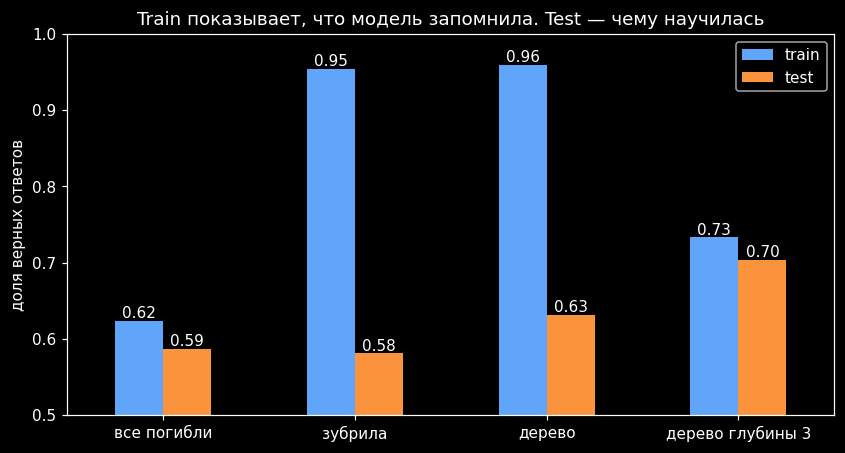

In [ ]:
import matplotlib.pyplot as plt
plt.style.use("dark_background")

ax = scores.plot.bar(rot=0, figsize=(9, 4.5), ylim=(0.5, 1), color=["#60a5fa", "#fb923c"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("доля верных ответов")
ax.set_title("Train показывает, что модель запомнила. Test — чему научилась")
plt.show()

**Главный вывод.** Качество модели меряют только на данных, которых она не видела. Высокая доля верных на train и заметно меньшая на test — признак **переобучения**: модель запомнила train вместо того, чтобы найти закономерность.

**Вопрос** А если бы данных для обучения было в 10 раз больше — разрыв между train и test у глубокого дерева стал бы больше или меньше?

**Посложнее** Дерево глубины 3 на test лучше глубокого. Давайте переберём `max_depth` от 1 до 20 и возьмём тот, где на test лучше всего. Что здесь не так?

<details>
<summary>Показать ответ</summary>

Скорее меньше. Запомнить в 10 раз больше пассажиров труднее, а общие закономерности (первый класс выживал чаще) проявляются сильнее, и случайности на их фоне весят меньше. Больше данных — одно из главных лекарств от переобучения. Остальные — на занятии 10.

★ Подбирая `max_depth` по test, мы подсматриваем в test: он становится частью обучения, и оценка на нём получается завышенной. Для подбора настроек откладывают третью часть данных — валидационную выборку. Об этом тоже на занятии 10.

</details>

## Главное после урока

```python
X = data[features]                  # признаки: что знаем про объект заранее
y = data["target"]                  # таргет: что предсказываем
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(max_depth=3)   # любая модель sklearn
model.fit(X_train, y_train)                   # обучить на train
y_pred = model.predict(X_test)                # предсказать для новых объектов
model.score(X_train, y_train), model.score(X_test, y_test)   # сравнить
```

1. Задача ML — это три ответа: что дано (объекты и признаки), что предсказываем (таргет: число — регрессия, класс — классификация), как проверяем.
2. Модель — функция с параметрами. Обучение — подбор параметров, при которых функция потерь на train минимальна.
3. Проверяем только на test. Хорошо на train и плохо на test — модель запомнила, а не научилась.

### Термины занятия

| Термин | Что это |
| --- | --- |
| Объект | то, про что делаем предсказание; строка таблицы |
| Признак | то, что известно про объект до предсказания; столбец |
| Таргет (целевая переменная) | то, что предсказываем |
| Обучение с учителем | учимся на объектах, для которых ответ известен |
| Регрессия | таргет — число |
| Классификация | таргет — класс из списка |
| Модель | функция «признаки → предсказание» с параметрами |
| Функция потерь | число, которое показывает, насколько модель ошибается |
| Train / test | часть данных для обучения / часть для проверки |
| Переобучение | хорошо на train, плохо на test |
| Утечка | признак, в котором подсмотрен ответ |